# Caching in LLM Systems: KV Cache, Prompt Caching, Semantic Caching and CAG

> **Who is this for:** learners who know what an LLM does (it predicts the next token) and now want to understand *why* real LLM systems are fast and cheap enough to use, and what "caching" means at each level of the stack.
>
> **What you will learn:**
> - what the **KV cache** is, built from zero with a tiny attention layer in numpy, and how much work it saves
> - the two phases of generation (**prefill** and **decode**) and why decode is limited by memory speed, not math speed
> - how to **calculate KV cache memory**, and how **MQA, GQA, MLA, sliding-window attention** and **hybrid linear-attention layers** shrink it
> - **KV cache management at scale**: PagedAttention, prefix sharing (RadixAttention / automatic prefix caching), eviction (LRU), KV quantization, offloading to CPU/SSD, KV-aware routing, disaggregated prefill/decode, chunked prefill
> - **prompt caching** at the API level, and a cost calculator (with made-up prices)
> - **semantic caching**: how to build one, how to pick the similarity threshold, and its privacy and staleness risks
> - **Cache-Augmented Generation (CAG)**: preload knowledge once, reuse its KV cache, and when that beats RAG
> - **speculative decoding vs quantization**: what each one trades away, with a small simulation
> - how to **measure** all of it: TTFT, inter-token latency, tokens/sec, cache hit rate, cost per 1M tokens
>
> **Prerequisites:** [Start Here: How LLMs Work](00_start_here_how_llms_work.ipynb) (tokens, attention, generation). This notebook goes deeper on caching than the survey in [LLM Inference Optimization](13_inference_optimization.ipynb), which you can read before or after. Helpful: [LLM Architecture Innovations](14_llm_architecture_innovations.ipynb) and [RAG Fundamentals](02_rag/01_rag_fundamentals.ipynb).
>
> **Time needed:** about 1.5-2 hours to read and play. The notebook itself runs in well under a minute.
>
> **Runs on:** CPU, no API key, no internet. Every "model" here is a tiny toy (random weights or small probability tables). Every price is **made-up and only for illustration**.

### The big picture: caching happens at four levels

One sentence for each word first:
- A **cache** is a place where you keep a result you already computed, so the next time you need it you can look it up instead of computing it again.
- A **cache hit** means the result was found in the cache. A **cache miss** means it was not, so you have to do the full work.
- The **hit rate** is the share of lookups that were hits.

```mermaid
flowchart LR
    U[User question] --> S{"Semantic or exact-match cache<br/>(whole answers)"}
    S -- hit --> A[Return stored answer]
    S -- miss --> P{"Prompt / prefix cache<br/>(provider or serving engine)"}
    P -- "prefix hit" --> D[Skip prefill for cached part]
    P -- miss --> F[Full prefill]
    D --> K["KV cache inside the model<br/>(one entry per token)"]
    F --> K
    K --> G[Decode tokens one by one]
```

| Level | What is stored | Section |
|---|---|---|
| KV cache | the attention keys and values of every token, inside one request | 1-4 |
| Prefix / prompt cache | the KV cache of a shared prompt start, reused across requests | 4, 5 |
| Semantic cache | whole final answers, looked up by meaning | 6 |
| CAG | a whole knowledge base, prefilled once and reused for many questions | 7 |

## 0. Setup

We only need numpy, pandas, matplotlib and scikit-learn. We fix the random seed so you get the same numbers every time.

In [1]:
import time, math, random, hashlib                       # standard-library helpers
from collections import OrderedDict, Counter, deque     # small data structures
import numpy as np                                       # arrays and math
import pandas as pd                                      # tables
import matplotlib.pyplot as plt                          # plots
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

SEED = 42
random.seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
# one fixed colour order for every plot (colour-blind-checked palette)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (6.5, 3.6), "axes.prop_cycle": plt.cycler(color=COLORS),
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9,
})
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.5.4 | pandas 3.1.1


## 1. What the KV cache is, from zero

**What it is:** while an LLM writes an answer, it stores two small vectors for every token it has already seen: a **key (K)** and a **value (V)**. This store is the **KV cache**. Thanks to it, each new token only needs work for *itself*, not for the whole text again.

**Simple analogy:** you are writing a long essay and, before each new word, you re-read the whole essay. That is slow. Instead you keep short notes on a sticky pad, one note per word so far. For the next word you only glance at the notes and add one new note. The sticky pad is the KV cache.

**How it works (attention in three lines):** each token is turned into three vectors.
- a **query (Q)**: "what am I looking for?"
- a **key (K)**: "what do I contain?" (used to decide *how much* to look at a token)
- a **value (V)**: "what information do I give?" (what is actually passed on)

The newest token compares its query with the keys of all earlier tokens, turns the scores into weights (softmax), and takes a weighted average of their values.

The important fact: **the K and V of an old token never change** when new tokens arrive (because generation only looks backwards; this is called **causal** attention). So computing them again at every step is pure waste. We compute them once and keep them.

```
step 1:  "The cat"           -> compute K,V for "The","cat"     -> cache = [The, cat]
step 2:  + "sat"             -> compute K,V for "sat" only       -> cache = [The, cat, sat]
step 3:  + "on"              -> compute K,V for "on" only        -> cache = [The, cat, sat, on]
```

Let us build a tiny attention "language model" in numpy and generate tokens both ways.

In [2]:
class TinyAttentionLM:
    """A 1-layer, 1-head attention 'language model' with RANDOM weights.
    It is not trained, so its output is gibberish token ids. It only exists so we can
    see, count and time the work a real model does."""

    def __init__(self, vocab=64, d=32, max_len=4096, seed=0):
        r = np.random.default_rng(seed)
        s = 1 / np.sqrt(d)
        self.d = d
        self.tok_emb = r.normal(0, 1, (vocab, d))          # one vector per token id
        self.pos_emb = r.normal(0, 0.5, (max_len, d))      # one vector per position
        self.Wq, self.Wk, self.Wv, self.Wo = (r.normal(0, s, (d, d)) for _ in range(4))
        self.W_out = r.normal(0, s, (d, vocab))            # hidden state -> score per token id
        self.kv_rows_computed = 0                          # counter: K/V rows we computed

    def embed(self, tokens, start_pos=0):
        tokens = np.asarray(tokens)
        return self.tok_emb[tokens] + self.pos_emb[start_pos:start_pos + len(tokens)]

    def attend(self, q, K, V):
        scores = q @ K.T / np.sqrt(self.d)                 # how well q matches each key
        scores = scores - scores.max(axis=-1, keepdims=True)
        w = np.exp(scores); w = w / w.sum(axis=-1, keepdims=True)   # softmax -> weights
        return w @ V                                       # weighted average of values

    def logits_from(self, x_last, attn_out):
        return (x_last + attn_out @ self.Wo) @ self.W_out  # residual + output projection

    # Way 1: NO cache. Recompute K and V for the WHOLE sequence at every step.
    def next_logits_no_cache(self, tokens):
        x = self.embed(tokens)
        K, V = x @ self.Wk, x @ self.Wv
        self.kv_rows_computed += len(tokens)
        q = x[-1:] @ self.Wq                               # only the last token predicts the next one
        return self.logits_from(x[-1:], self.attend(q, K, V))[0]

    # Way 2: WITH a KV cache. Compute K and V only for the NEW tokens and append them.
    def next_logits_with_cache(self, new_tokens, cache):
        start = len(cache["K"])                            # position of the first new token
        x = self.embed(new_tokens, start_pos=start)
        cache["K"] = np.vstack([cache["K"], x @ self.Wk])
        cache["V"] = np.vstack([cache["V"], x @ self.Wv])
        self.kv_rows_computed += len(new_tokens)
        q = x[-1:] @ self.Wq
        return self.logits_from(x[-1:], self.attend(q, cache["K"], cache["V"]))[0]

def empty_cache(d):
    return {"K": np.zeros((0, d)), "V": np.zeros((0, d))}

model = TinyAttentionLM()
print("model width d =", model.d, "| vocabulary =", model.tok_emb.shape[0], "token ids")

model width d = 32 | vocabulary = 64 token ids


In [3]:
def generate(model, prompt, n_new, use_cache):
    """Greedy generation: always pick the highest-scoring next token."""
    tokens = list(prompt)
    cache = empty_cache(model.d) if use_cache else None
    new_part = tokens                       # first step: the whole prompt is "new"
    for _ in range(n_new):
        if use_cache:
            logits = model.next_logits_with_cache(new_part, cache)
        else:
            logits = model.next_logits_no_cache(tokens)
        nxt = int(np.argmax(logits))
        tokens.append(nxt)
        new_part = [nxt]                    # next step: only this one token is new
    return tokens[len(prompt):]

prompt = list(rng.integers(0, 64, size=20))     # a random 20-token "prompt"

model.kv_rows_computed = 0
t0 = time.perf_counter(); out_no = generate(model, prompt, 200, use_cache=False); t_no = time.perf_counter() - t0
rows_no = model.kv_rows_computed

model.kv_rows_computed = 0
t0 = time.perf_counter(); out_kv = generate(model, prompt, 200, use_cache=True); t_kv = time.perf_counter() - t0
rows_kv = model.kv_rows_computed

print("first 15 generated ids (no cache):", out_no[:15])
print("first 15 generated ids (KV cache):", out_kv[:15])
print("outputs identical:", out_no == out_kv)
print(f"K/V rows computed  no cache: {rows_no:>7,}   with cache: {rows_kv:>5,}   ({rows_no / rows_kv:.0f}x less work)")
print(f"time               no cache: {t_no*1000:>7.1f} ms   with cache: {t_kv*1000:.1f} ms")
print("(at this tiny size Python overhead hides much of the gap; it grows with length, see the next plot)")

first 15 generated ids (no cache): [42, 53, 5, 53, 11, 6, 53, 11, 17, 38, 39, 10, 57, 20, 9]
first 15 generated ids (KV cache): [42, 53, 5, 53, 11, 6, 53, 11, 17, 38, 39, 10, 57, 20, 9]
outputs identical: True
K/V rows computed  no cache:  23,900   with cache:   219   (109x less work)
time               no cache:    14.4 ms   with cache: 9.3 ms
(at this tiny size Python overhead hides much of the gap; it grows with length, see the next plot)


**What just happened?** Both ways produced **exactly the same tokens**. The KV cache is not an approximation: it gives the same answer and only removes repeated work. Without the cache we computed K and V for 20 + 21 + 22 + ... + 219 rows (about 24,000). With the cache we computed each token's K and V once (219 rows).

In a real model with many layers the saving is even bigger, because in layer 2 and above the K and V depend on the outputs of the layer below, which would also have to be recomputed.

Let us see how the work grows with the length of the text.

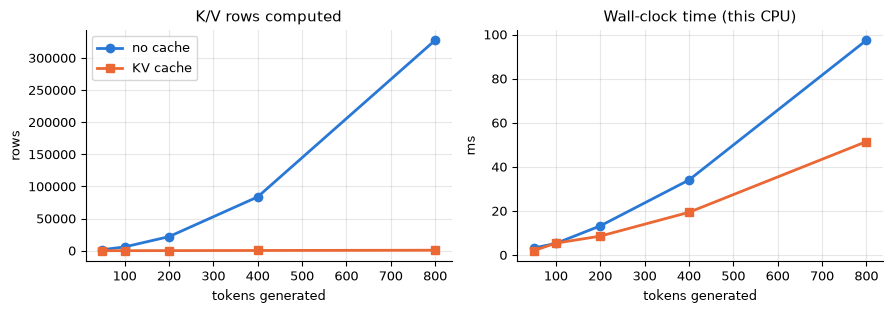

 tokens generated  rows no cache  rows KV cache  ms no cache  ms KV cache
               50           1725             59          3.2          2.0
              100           5950            109          5.3          5.4
              200          21900            209         13.2          8.6
              400          83800            409         34.0         19.4
              800         327600            809         97.4         51.4


In [4]:
lengths = [50, 100, 200, 400, 800]
rows = {"no cache": [], "KV cache": []}; times = {"no cache": [], "KV cache": []}
small_prompt = list(rng.integers(0, 64, size=10))
for n in lengths:
    for name, flag in [("no cache", False), ("KV cache", True)]:
        model.kv_rows_computed = 0
        t0 = time.perf_counter(); generate(model, small_prompt, n, use_cache=flag)
        times[name].append((time.perf_counter() - t0) * 1000)
        rows[name].append(model.kv_rows_computed)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for name, marker in [("no cache", "o"), ("KV cache", "s")]:
    axes[0].plot(lengths, rows[name], marker=marker, label=name)
    axes[1].plot(lengths, times[name], marker=marker, label=name)
axes[0].set(title="K/V rows computed", xlabel="tokens generated", ylabel="rows")
axes[1].set(title="Wall-clock time (this CPU)", xlabel="tokens generated", ylabel="ms")
axes[0].legend(); plt.tight_layout(); plt.show()
print(pd.DataFrame({"tokens generated": lengths, "rows no cache": rows["no cache"], "rows KV cache": rows["KV cache"],
                    "ms no cache": np.round(times["no cache"], 1), "ms KV cache": np.round(times["KV cache"], 1)}).to_string(index=False))

Without a cache the work grows like **n squared** (double the length, about 4 times the work). With a cache it grows like **n** (double the length, double the work).

**The catch:** the cache must be stored somewhere. It grows by one K and one V per token, per layer. For big models and long texts it becomes many gigabytes. That memory cost is what most of this notebook is about.

| | Without KV cache | With KV cache |
|---|---|---|
| Work per new token | grows with the whole text | constant projection work (attention still reads all past K/V) |
| Memory | small | grows with every token |
| Output | same | same |
| Used in practice? | almost never for generation | always |

## 2. Prefill vs decode: the two phases of generation

**What it is:**
- **Prefill** = the model reads your whole prompt in one go and fills the KV cache for all prompt tokens. All prompt tokens are processed *in parallel*, as one big matrix multiplication.
- **Decode** = the model then writes the answer *one token at a time*. Each step processes just one new token per request.

**Simple analogy:** prefill is reading the whole exam question at once. Decode is writing the answer word by word, and you cannot write word 5 before word 4.

```mermaid
flowchart LR
    P["Prompt: 2,000 tokens"] --> PF["PREFILL<br/>one big parallel pass<br/>fills KV cache"]
    PF --> T1["token 1"]
    T1 --> T2["token 2"] --> T3["token 3"] --> T4["... (DECODE, one at a time)"]
```

Two latency numbers come from these phases:
- **TTFT (time to first token)** is mostly prefill time (plus waiting in a queue).
- **ITL (inter-token latency)** is the time between two output tokens. It is decode time.

### Why decode is "memory-bandwidth bound"

**Memory bandwidth** is how many bytes per second the chip can move from its memory to its compute units. To produce **one** token, the chip must read **all** model weights (and the KV cache) from memory, but it only does a little math with each weight. So the chip spends most of its time waiting for data, not computing. We call this **memory-bandwidth bound**. Prefill, on the other hand, reuses every weight for thousands of tokens at once, so it is **compute bound**.

We can see the same effect on your CPU: multiplying a big weight matrix by 1 vector vs by 256 vectors.

In [5]:
try:                                                      # use 1 CPU thread so timings are less noisy
    from threadpoolctl import threadpool_limits            # (installed together with scikit-learn)
    one_thread = threadpool_limits(limits=1)
except ImportError:
    one_thread = None

d = 4096
W = rng.standard_normal((d, d)).astype(np.float32)        # a 64 MB "weight matrix"
rows_out = []
for batch in [1, 4, 16, 64, 256]:
    X = rng.standard_normal((batch, d)).astype(np.float32)  # 'batch' tokens at once
    X @ W                                                   # warm-up
    runs = []
    for _ in range(7):                                      # time 7 runs, keep the fastest (least noise)
        t0 = time.perf_counter(); X @ W; runs.append(time.perf_counter() - t0)
    ms = min(runs) * 1000
    rows_out.append({"tokens processed together": batch, "total ms": round(ms, 2),
                     "ms per token": round(ms / batch, 3),
                     "math per byte of weights read": round(2 * batch / 4, 1)})   # FLOPs / bytes (float32 = 4 bytes)
if one_thread is not None:
    one_thread.restore_original_limits()
print(pd.DataFrame(rows_out).to_string(index=False))
print("(exact times depend on your CPU; look at the trend in 'ms per token')")
print("'math per byte' is also called ARITHMETIC INTENSITY: work done per byte loaded. Low = memory bound.")
print("\nThe weights are read once per multiplication, so many tokens share the cost.")
print("Decode with 1 token is like the first row: slow per token. Prefill is like the last row.")

 tokens processed together  total ms  ms per token  math per byte of weights read
                         1      3.08         3.076                            0.5
                         4      7.31         1.827                            2.0
                        16     11.12         0.695                            8.0
                        64     28.18         0.440                           32.0
                       256    104.60         0.409                          128.0
(exact times depend on your CPU; look at the trend in 'ms per token')
'math per byte' is also called ARITHMETIC INTENSITY: work done per byte loaded. Low = memory bound.

The weights are read once per multiplication, so many tokens share the cost.
Decode with 1 token is like the first row: slow per token. Prefill is like the last row.


Now a back-of-the-envelope estimate for a real model. The hardware numbers below are **made-up round numbers** that are only roughly in the range of a modern data-center GPU.

In [6]:
params        = 7e9      # a 7-billion-parameter model
bytes_per_w   = 2        # FP16/BF16 weights = 2 bytes each
bandwidth     = 3e12     # ILLUSTRATIVE: 3 TB/s memory bandwidth
compute       = 1e15     # ILLUSTRATIVE: 1,000 TFLOP/s of FP16 math

read_ms    = params * bytes_per_w / bandwidth * 1000   # time to read all weights once
compute_ms = 2 * params / compute * 1000               # about 2 FLOPs per weight per token
print(f"decode, batch 1: read weights {read_ms:.2f} ms vs do the math {compute_ms:.3f} ms per token")
print(f"-> memory takes ~{read_ms / compute_ms:.0f}x longer than math. Upper bound ~{1000 / read_ms:.0f} tokens/s for one user.")
print("Batching 64 users reads the weights once for 64 tokens -> far better use of the chip.")

decode, batch 1: read weights 4.67 ms vs do the math 0.014 ms per token
-> memory takes ~333x longer than math. Upper bound ~214 tokens/s for one user.
Batching 64 users reads the weights once for 64 tokens -> far better use of the chip.


**Why this matters for caching:** in decode, every token also reads the **whole KV cache** of its request. Bigger KV cache = more bytes to read per token = slower decode, and fewer requests fit in memory at once. Making the KV cache small is therefore a speed win *and* a capacity win.

| | Prefill | Decode |
|---|---|---|
| Tokens per step | all prompt tokens at once | 1 per request |
| Limited by | compute (math) | memory bandwidth |
| Affects | TTFT | inter-token latency, throughput |
| Main tricks | prefix caching, chunked prefill, FlashAttention | batching, smaller KV cache, quantization, speculative decoding |

## 3. KV cache memory math, and how modern attention shrinks it

For every token, every layer stores one K vector and one V vector per **KV head** (a head is one independent attention "channel"). So:

$$\text{KV bytes} = 2 \times \text{layers} \times \text{kv\_heads} \times \text{head\_dim} \times \text{seq\_len} \times \text{batch} \times \text{bytes per number}$$

The 2 is for K and V. The survey notebook [13_inference_optimization](13_inference_optimization.ipynb) has the same formula with real model configs. Here is a small calculator.

In [7]:
DTYPE_BYTES = {"fp32": 4, "fp16/bf16": 2, "fp8": 1, "int8": 1, "int4": 0.5}

def kv_cache_bytes(layers, kv_heads, head_dim, seq_len, batch=1, dtype="fp16/bf16"):
    """Classic K+V cache size for MHA / GQA / MQA."""
    return 2 * layers * kv_heads * head_dim * seq_len * batch * DTYPE_BYTES[dtype]

def gib(b):
    return b / 1024**3

# An example 8B-class model shape (32 layers, 32 query heads, head_dim 128)
ex = dict(layers=32, head_dim=128)
print(f"per token (MHA, 32 kv heads, fp16): {kv_cache_bytes(kv_heads=32, seq_len=1, **ex) / 1024:.0f} KiB")
print(f"one 32k-token chat   : {gib(kv_cache_bytes(kv_heads=32, seq_len=32_768, **ex)):.1f} GiB")
print(f"16 such chats at once: {gib(kv_cache_bytes(kv_heads=32, seq_len=32_768, batch=16, **ex)):.1f} GiB  (more than one GPU holds)")

per token (MHA, 32 kv heads, fp16): 512 KiB
one 32k-token chat   : 16.0 GiB
16 such chats at once: 256.0 GiB  (more than one GPU holds)


That last number is why the field invented ways to store less per token.

### MHA vs MQA vs GQA vs MLA

- **MHA (multi-head attention):** every query head has its own K and V head. Most memory.
- **MQA (multi-query attention):** all query heads *share one* K/V head. Smallest classic cache, but can lose some quality.
- **GQA (grouped-query attention):** query heads are split into groups; each group shares one K/V head (for example 32 query heads, 8 KV heads). A middle ground, used by many open models (as of late 2026, GQA is the most common choice).
- **MLA (multi-head latent attention, from DeepSeek-V2):** instead of caching full K and V, cache one small **compressed vector** (a "latent") per token per layer, and rebuild K and V from it when needed with a learned "up-projection" matrix. Plus a small extra piece for position information (RoPE).

**Simple analogy:** MHA = every student keeps a full copy of the notes. GQA = one copy per study group. MQA = one copy for the whole class. MLA = everyone keeps a short summary that can be expanded back into notes when needed.

```
MHA:   q1 q2 q3 q4 q5 q6 q7 q8         GQA:   q1 q2 q3 q4 | q5 q6 q7 q8        MQA:  q1 ... q8
       |  |  |  |  |  |  |  |                 \  |  |  /   \  |  |  /              \  |  /
       kv kv kv kv kv kv kv kv                   kv            kv                     kv
       (8 KV heads cached)                    (2 KV heads cached)                 (1 KV head)

MLA:   hidden state --(down-project)--> latent c  [CACHE THIS, small]
                                       latent c --(up-project)--> K and V for all heads
```

In [8]:
def mla_cache_bytes(layers, latent_dim, rope_dim, seq_len, batch=1, dtype="fp16/bf16"):
    """MLA stores one latent vector + one small RoPE key per token per layer (no factor 2)."""
    return layers * (latent_dim + rope_dim) * seq_len * batch * DTYPE_BYTES[dtype]

seq = 32_768
variants = {
    "MHA (32 KV heads)": kv_cache_bytes(kv_heads=32, seq_len=seq, **ex),
    "GQA (8 KV heads)":  kv_cache_bytes(kv_heads=8,  seq_len=seq, **ex),
    "MQA (1 KV head)":   kv_cache_bytes(kv_heads=1,  seq_len=seq, **ex),
    # latent 512 + RoPE part 64: sizes similar in spirit to DeepSeek-V2's published setup
    "MLA (latent 512 + 64)": mla_cache_bytes(32, 512, 64, seq),
}
mha = variants["MHA (32 KV heads)"]
table = pd.DataFrame([{"attention type": k, "values per token per layer": int(v / seq / 32 / 2),
                       "GiB for one 32k chat (fp16)": round(gib(v), 2), "vs MHA": f"{mha / v:.1f}x smaller"}
                      for k, v in variants.items()])
print(table.to_string(index=False))
print("\n(The MLA row is a hypothetical: our example model shape with MLA sizes like DeepSeek-V2.)")

       attention type  values per token per layer  GiB for one 32k chat (fp16)        vs MHA
    MHA (32 KV heads)                        8192                        16.00  1.0x smaller
     GQA (8 KV heads)                        2048                         4.00  4.0x smaller
      MQA (1 KV head)                         256                         0.50 32.0x smaller
MLA (latent 512 + 64)                         576                         1.12 14.2x smaller

(The MLA row is a hypothetical: our example model shape with MLA sizes like DeepSeek-V2.)


A tiny MLA demo in numpy: we cache only the latent, and rebuild K and V from it exactly when attention needs them.

In [9]:
d_model, n_heads, d_head, d_latent = 64, 4, 16, 16
r = np.random.default_rng(1)
W_down = r.normal(0, 0.1, (d_model, d_latent))            # compress: hidden -> latent
W_up_k = r.normal(0, 0.1, (d_latent, n_heads * d_head))   # expand latent -> keys (all heads)
W_up_v = r.normal(0, 0.1, (d_latent, n_heads * d_head))   # expand latent -> values (all heads)

H = r.normal(size=(10, d_model))          # hidden states of 10 tokens
C = H @ W_down                            # <- the ONLY thing MLA keeps in the cache
K_rebuilt, V_rebuilt = C @ W_up_k, C @ W_up_v
K_direct = H @ (W_down @ W_up_k)          # same thing computed directly

print("cached numbers, MHA style (K+V):", 10 * 2 * n_heads * d_head)
print("cached numbers, MLA latent     :", C.size, f"-> {10 * 2 * n_heads * d_head / C.size:.0f}x smaller")
print("rebuilt K equals direct K:", np.allclose(K_rebuilt, K_direct))

cached numbers, MHA style (K+V): 1280
cached numbers, MLA latent     : 160 -> 8x smaller
rebuilt K equals direct K: True


In real MLA the up-projection for K can even be **absorbed** (multiplied in advance) into the query projection, so the full K never has to be built. The cost: a slightly more complex layer that must be designed in **before training**. You cannot switch an existing GQA model to MLA for free (there is research on converting models, but it needs extra training).

### Sliding-window attention and hybrid layers

- **Sliding-window attention:** each token only looks at the last W tokens (for example 4,096). The cache never grows past W tokens per layer. Many models mix sliding-window layers with a few full-attention layers so they can still reach far back.
- **Hybrid linear-attention / state-space layers:** layers like Mamba-style state-space layers or linear attention keep a **fixed-size state** instead of a list of K/V per token. Memory does not grow with length. Hybrid models (for example Jamba) keep only a few normal attention layers, so only those layers have a growing cache.

**Simple analogy:** sliding window = you only keep the last 50 pages of notes. Linear attention = you keep one running summary page that you keep updating.

The plot below compares how cache memory grows with length for one request (log scale).

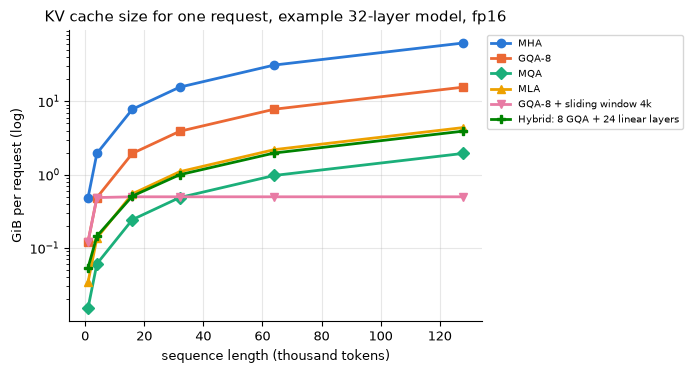

In [10]:
seqs = np.array([1_000, 4_000, 16_000, 32_000, 64_000, 128_000])
WINDOW = 4_096
lin_state = 32 * 128 * 128 * 2          # linear-attention state per layer: heads x d x d numbers, fp16 bytes

curves = {
    "MHA":                         [kv_cache_bytes(kv_heads=32, seq_len=s, **ex) for s in seqs],
    "GQA-8":                       [kv_cache_bytes(kv_heads=8, seq_len=s, **ex) for s in seqs],
    "MQA":                         [kv_cache_bytes(kv_heads=1, seq_len=s, **ex) for s in seqs],
    "MLA":                         [mla_cache_bytes(32, 512, 64, s) for s in seqs],
    "GQA-8 + sliding window 4k":   [kv_cache_bytes(kv_heads=8, seq_len=min(s, WINDOW), **ex) for s in seqs],
    "Hybrid: 8 GQA + 24 linear layers": [kv_cache_bytes(layers=8, kv_heads=8, head_dim=128, seq_len=s) + 24 * lin_state for s in seqs],
}
fig, ax = plt.subplots(figsize=(7, 3.8))
markers = "osD^vP"
for (name, ys), m in zip(curves.items(), markers):
    ax.plot(seqs / 1000, [gib(y) for y in ys], marker=m, label=name)
ax.set_yscale("log"); ax.set(xlabel="sequence length (thousand tokens)", ylabel="GiB per request (log)",
                             title="KV cache size for one request, example 32-layer model, fp16")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.0, 1.0)); plt.tight_layout(); plt.show()

| Technique | What it caches | Cache growth | Main trade-off | Must be trained in? |
|---|---|---|---|---|
| MHA | full K,V for every head | linear, largest | none (baseline quality) | - |
| GQA | K,V per group of heads | linear, 4-8x smaller | tiny quality cost | yes (or "uptrained") |
| MQA | one K,V head | linear, smallest classic | more quality risk | yes |
| MLA | small latent per token | linear, very small | more complex kernels | yes |
| Sliding window | last W tokens only | flat after W | forgets far context (unless mixed with global layers) | yes |
| Linear / state-space layers | fixed-size state | flat | weaker exact recall of far details | yes |

You choose these when you **pick a model**. Section 4 is about what you control when you **serve** a model.

## 4. KV cache management at scale

When one server handles hundreds of users, the KV cache becomes a shared memory pool that must be split, reused, evicted, compressed and moved. Each subsection below is one idea.

### 4.1 PagedAttention: memory blocks like operating-system pages

**What it is:** PagedAttention (introduced with vLLM) stores each request's KV cache in small fixed-size **blocks** (for example 16 tokens each) that can sit anywhere in memory. A **block table** per request records which physical blocks belong to it, in order.

**Simple analogy:** a library that stores a book's chapters on any free shelf, with an index card that says "chapter 1 is on shelf 7, chapter 2 on shelf 2". No need to find one long empty shelf.

**The problem it solves: fragmentation.** **Fragmentation** means memory that is free or reserved but cannot be used.
- *Internal fragmentation:* you do not know how long an answer will be, so the old way reserved the maximum length (say 2,048 tokens) up front. Most of that space stays empty.
- *External fragmentation:* after requests finish, free memory is split into small gaps, and a new large request does not fit in any single gap.

First, external fragmentation in a 100-slot toy memory:

In [11]:
# contiguous memory: each request needs ONE unbroken range of slots
memory = ["A"] * 30 + ["B"] * 20 + ["C"] * 30 + ["D"] * 20      # 100 slots, full
memory = [None if x in ("B", "D") else x for x in memory]        # B and D finish

def largest_gap(mem):
    best = cur = 0
    for x in mem:
        cur = cur + 1 if x is None else 0
        best = max(best, cur)
    return best

free = memory.count(None)
print("free slots:", free, "| largest single gap:", largest_gap(memory))
print("new request needs 35 slots -> contiguous:", "fits" if largest_gap(memory) >= 35 else "DOES NOT FIT",
      "| paged (any free slots):", "fits" if free >= 35 else "does not fit")

free slots: 40 | largest single gap: 20
new request needs 35 slots -> contiguous: DOES NOT FIT | paged (any free slots): fits


Now a tiny block allocator, the heart of PagedAttention. Blocks are handed out only when a request actually needs them.

In [12]:
class BlockAllocator:
    """Toy PagedAttention memory manager: fixed-size blocks + one block table per request."""
    def __init__(self, n_blocks, block_size):
        self.free = list(range(n_blocks))   # physical block ids that are free
        self.block_size = block_size
        self.tables = {}                    # request id -> list of physical block ids (in order)
        self.lengths = {}                   # request id -> number of tokens stored

    def append_tokens(self, rid, n):
        table = self.tables.setdefault(rid, [])
        length = self.lengths.get(rid, 0)
        for _ in range(n):
            if length % self.block_size == 0:          # last block is full (or no block yet)
                if not self.free:
                    raise MemoryError("out of KV blocks")
                table.append(self.free.pop(0))         # grab ANY free block
            length += 1
        self.lengths[rid] = length

    def release(self, rid):                            # request finished: give blocks back
        self.free.extend(self.tables.pop(rid)); self.lengths.pop(rid)

alloc = BlockAllocator(n_blocks=12, block_size=4)
alloc.append_tokens("A", 6)      # A's prompt
alloc.append_tokens("B", 9)      # B's prompt
alloc.append_tokens("A", 5)      # A generates 5 more tokens -> gets a block after B's
print("block tables:", alloc.tables, "| free:", alloc.free)
alloc.release("B")
alloc.append_tokens("C", 30)     # C reuses B's old blocks, scattered is fine
print("after B leaves and C arrives:", alloc.tables, "| free:", alloc.free)

block tables: {'A': [0, 1, 5], 'B': [2, 3, 4]} | free: [6, 7, 8, 9, 10, 11]
after B leaves and C arrives: {'A': [0, 1, 5], 'C': [6, 7, 8, 9, 10, 11, 2, 3]} | free: [4]


In [13]:
CAPACITY, MAX_LEN, BLOCK = 16_384, 2_048, 16          # token slots, reserved max, block size
final_lengths = rng.integers(50, 1_200, size=500)      # real final lengths (unknown in advance)

# Old way: reserve MAX_LEN contiguous slots per request
n_old = CAPACITY // MAX_LEN
util_old = final_lengths[:n_old].sum() / (n_old * MAX_LEN)

# Paged way: each request uses ceil(length / BLOCK) blocks
blocks_needed = np.ceil(final_lengths / BLOCK).astype(int)
n_paged = int(np.searchsorted(np.cumsum(blocks_needed) * BLOCK, CAPACITY, side="right"))
util_paged = final_lengths[:n_paged].sum() / (blocks_needed[:n_paged].sum() * BLOCK)

print(pd.DataFrame([
    {"approach": "reserve max length", "requests that fit at once": n_old, "memory really used": f"{util_old:.0%}"},
    {"approach": "paged blocks of 16", "requests that fit at once": n_paged, "memory really used": f"{util_paged:.0%}"},
]).to_string(index=False))

          approach  requests that fit at once memory really used
reserve max length                          8                29%
paged blocks of 16                         27                99%


More requests in memory at once means bigger decode batches, which (from section 2) means much better use of the chip. The vLLM paper reports that this was a main reason for its throughput gains. The only waste left is the unused part of each request's *last* block.

### 4.2 Prefix sharing: automatic prefix caching and RadixAttention

**What it is:** many requests start with the **same tokens**: the same system prompt, the same tool definitions, the same document, or the earlier turns of the same chat. Their KV cache for that shared start (the **prefix**) is identical, so compute it once and let all requests point to the same blocks. This is **prefix caching**.

**Simple analogy:** 100 students read the same first chapter. Print it once and pass it around, instead of printing 100 copies.

Two common designs (as of late 2026):
- **Automatic prefix caching (vLLM):** give each full block a **hash** (a short fingerprint) computed from its tokens *and all tokens before it*. Same hash = same block = reuse.
- **RadixAttention (SGLang):** keep all cached sequences in a **radix tree** (a prefix tree where shared beginnings are stored once). A new request walks down the tree to find its longest cached prefix.

```mermaid
flowchart TD
    R(("root")) --> S["system prompt: 'You are a helpful support bot...'"]
    S --> U1["user 1: 'Where is my order?'"]
    S --> U2["user 2: 'Reset my password'"]
    U2 --> U2b["assistant reply + user 2 follow-up"]
    S --> F["few-shot examples"] --> U3["user 3: 'Translate this'"]
```

Here is block hashing with a chain, as in automatic prefix caching:

In [14]:
def block_hashes(tokens, block=BLOCK):
    """Hash each FULL block, chained with the previous block's hash.
    So a block only matches if everything before it matches too."""
    hashes, prev = [], ""
    for i in range(0, len(tokens) - len(tokens) % block, block):
        h = hashlib.sha256((prev + str(tokens[i:i + block])).encode()).hexdigest()[:12]
        hashes.append(h); prev = h
    return hashes

system_prompt = list(rng.integers(0, 50_000, size=480))     # 480 shared tokens (30 blocks)
few_shot      = list(rng.integers(0, 50_000, size=320))     # used by half of the requests
cache_blocks  = set()                                       # hashes of blocks already computed
computed_with, computed_without = 0, 0
for i in range(100):
    user = list(rng.integers(0, 50_000, size=int(rng.integers(20, 80))))
    req = system_prompt + (few_shot if i % 2 == 0 else []) + user
    hs = block_hashes(req)
    hit = 0
    for h in hs:                       # count matching blocks from the start
        if h not in cache_blocks:
            break
        hit += 1
    computed_with += len(req) - hit * BLOCK
    computed_without += len(req)
    cache_blocks.update(hs)            # store this request's full blocks for later requests
print(f"prefill tokens without prefix caching: {computed_without:,}")
print(f"prefill tokens with prefix caching   : {computed_with:,}  ({1 - computed_with / computed_without:.0%} saved)")

prefill tokens without prefix caching: 69,122
prefill tokens with prefix caching   : 5,922  (91% saved)


And a tiny prefix tree (the idea behind RadixAttention), working at word level so it is easy to read:

In [15]:
class PrefixTree:
    """Token-level prefix tree. SGLang's radix tree is the same idea, with runs merged into one node."""
    def __init__(self):
        self.root = {}
    def insert(self, tokens):
        node = self.root
        for t in tokens:
            node = node.setdefault(t, {})
    def longest_match(self, tokens):
        node, n = self.root, 0
        for t in tokens:
            if t not in node:
                break
            node, n = node[t], n + 1
        return n

tree = PrefixTree()
sys_p = "you are a helpful support bot for acme shop .".split()
tree.insert(sys_p + "where is my order ?".split())
tree.insert(sys_p + "reset my password please".split())
for q in ["where is my parcel ?", "reset my password please now", "hello"]:
    toks = sys_p + q.split()
    print(f"{q!r:32} -> reuse {tree.longest_match(toks):2d} of {len(toks)} tokens")

'where is my parcel ?'           -> reuse 13 of 15 tokens
'reset my password please now'   -> reuse 14 of 15 tokens
'hello'                          -> reuse 10 of 11 tokens


**When it helps most:** long shared system prompts, agents that resend the same tool list every step, multi-turn chat (each turn re-sends the history), many questions about the same document, and sampling several answers for the same prompt.

**When it does not help:** every prompt is unique from the first token (for example a timestamp or user id at the very start).

### 4.3 Eviction: what to throw out when memory is full

**What it is:** cached prefixes stay in memory after their request finishes, in case a later request needs them. When memory is full, the engine must **evict** (delete) something. An **eviction policy** decides what.
- **LRU (least recently used):** throw out the entry that was used longest ago. The most common default.
- **FIFO (first in, first out):** throw out the oldest entry, even if it is popular.
- **Random:** throw out any entry.

**Simple analogy:** your desk has room for 10 books. LRU = put back the book you have not opened for the longest time.

Real engines only evict blocks that **no running request is using**, and SGLang evicts **leaf** nodes of its tree first (the ends of sequences), so shared beginnings stay longer. Let us simulate hit rate when some prefixes are much more popular than others (a "Zipf" pattern, common in real traffic).

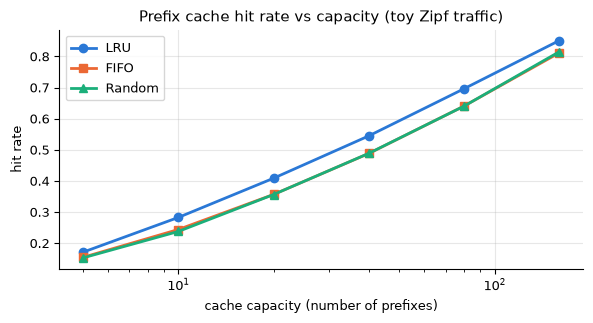

            LRU   FIFO  Random
capacity                      
5         0.171  0.155   0.153
10        0.283  0.244   0.238
20        0.409  0.357   0.356
40        0.545  0.488   0.489
80        0.696  0.641   0.640
160       0.851  0.812   0.815


In [16]:
def simulate(policy, capacity, requests, seed=0):
    r = random.Random(seed)
    cache, hits = OrderedDict(), 0
    for key in requests:
        if key in cache:
            hits += 1
            if policy == "LRU":
                cache.move_to_end(key)           # mark as recently used
            continue
        if len(cache) >= capacity:               # full: evict one entry
            if policy in ("LRU", "FIFO"):
                cache.popitem(last=False)        # front = least recent (LRU) or oldest (FIFO)
            else:
                del cache[r.choice(list(cache))]
        cache[key] = True
    return hits / len(requests)

n_prefixes = 300
popularity = 1 / np.arange(1, n_prefixes + 1) ** 1.0       # Zipf: prefix 1 is most popular
popularity /= popularity.sum()
reqs = list(rng.choice(n_prefixes, size=20_000, p=popularity))

caps = [5, 10, 20, 40, 80, 160]
res = {p: [simulate(p, c, reqs) for c in caps] for p in ["LRU", "FIFO", "Random"]}
fig, ax = plt.subplots(figsize=(6, 3.3))
for (p, ys), m in zip(res.items(), "os^"):
    ax.plot(caps, ys, marker=m, label=p)
ax.set(xscale="log", xlabel="cache capacity (number of prefixes)", ylabel="hit rate",
       title="Prefix cache hit rate vs capacity (toy Zipf traffic)")
ax.legend(); plt.tight_layout(); plt.show()
print(pd.DataFrame(res, index=caps).rename_axis("capacity").round(3).to_string())

LRU wins by a small margin here because it keeps popular items. The bigger lesson: **capacity matters most**, which is why the next three ideas (quantize, offload, route) all try to give the cache more effective room.

### 4.4 KV cache quantization (FP8 / INT8 / INT4 KV)

**What it is:** store each K and V number with fewer bits. FP16 uses 16 bits; **FP8** and **INT8** use 8 bits (half the memory); **INT4** uses 4 bits (a quarter). **Quantization** means rounding numbers to a smaller set of levels, plus a **scale** factor to map them back.

**Simple analogy:** saving a photo as a smaller JPEG. Much smaller, usually looks the same, but too much compression shows artefacts.

**How it works:** for each group of numbers (for example one token's K vector), find the largest absolute value, divide everything by a scale so it fits in the integer range, round, and store the integers plus the scale. FP8 KV cache is widely supported in serving engines (as of late 2026); INT4 KV usually needs more care (research such as KIVI quantizes keys per channel and values per token).

In [17]:
def fake_quantize(X, bits, axis):
    """Symmetric quantization: round to 2^(bits-1)-1 levels per group, then map back."""
    qmax = 2 ** (bits - 1) - 1
    scale = np.abs(X).max(axis=axis, keepdims=True) / qmax
    return np.round(X / scale).clip(-qmax, qmax) * scale

x = model.embed(list(rng.integers(0, 64, size=500)))      # 500 tokens of our toy model
K, V = x @ model.Wk, x @ model.Wv
q = x[-1:] @ model.Wq
ref = model.attend(q, K, V)                                # attention output with full precision

rows_q = []
for bits in [8, 4]:
    out = model.attend(q, fake_quantize(K, bits, axis=0), fake_quantize(V, bits, axis=1))
    err = np.linalg.norm(out - ref) / np.linalg.norm(ref)
    rows_q.append({"KV format": f"INT{bits}", "relative error of attention output": f"{err:.2%}"})
print(pd.DataFrame(rows_q).to_string(index=False))

print("\nMemory for one 32k chat, example model with GQA-8:")
for dt in ["fp16/bf16", "fp8", "int8", "int4"]:
    print(f"  {dt:10s}: {gib(kv_cache_bytes(kv_heads=8, seq_len=32_768, dtype=dt, **ex)):.2f} GiB")

KV format relative error of attention output
     INT8                              0.24%
     INT4                              4.99%

Memory for one 32k chat, example model with GQA-8:
  fp16/bf16 : 4.00 GiB
  fp8       : 2.00 GiB
  int8      : 2.00 GiB
  int4      : 1.00 GiB


**When to use:** memory is the bottleneck (long contexts, many users). Start with FP8 KV, check quality on your own evals, then consider INT4 for very long contexts. **When not to:** tasks where tiny errors in long-range recall matter a lot and you have spare memory.

### 4.5 Offloading: a tiered KV cache (GPU -> CPU -> SSD)

**What it is:** when GPU memory is full, instead of deleting old KV blocks, move them to a slower but bigger place: CPU RAM, then local SSD, then shared storage. When a request needs them again, load them back. Open-source projects such as **LMCache** build this kind of shared, tiered KV store for engines like vLLM.

**Simple analogy:** desk (GPU), bookshelf (CPU RAM), basement (SSD). Fetching from the basement is slow, but still faster than rewriting the book.

| Tier | Size | Speed | Typical use |
|---|---|---|---|
| GPU memory (HBM) | smallest | fastest | active requests |
| CPU RAM | bigger | slower (crosses PCIe or a similar link) | recently used prefixes |
| Local SSD | much bigger | slower still | popular documents, long chats |
| Remote / shared storage | huge | slowest | sharing caches across servers |

The key question is always: **is loading the cache back faster than recomputing it (prefill)?** All speeds below are **made-up round numbers** for illustration.

In [18]:
ctx_tokens = 20_000
kv_bytes = kv_cache_bytes(kv_heads=8, seq_len=ctx_tokens, **ex)    # example model, GQA-8, fp16
prefill_tok_per_s = 10_000                                          # ILLUSTRATIVE prefill speed
options = {"recompute (prefill again)": ctx_tokens / prefill_tok_per_s,
           "load from CPU RAM (25 GB/s)": kv_bytes / 25e9,          # ILLUSTRATIVE bandwidths
           "load from local SSD (5 GB/s)": kv_bytes / 5e9,
           "load from network storage (1 GB/s)": kv_bytes / 1e9}
print(f"KV cache for a {ctx_tokens:,}-token context: {gib(kv_bytes):.2f} GiB")
for k, s in options.items():
    print(f"  {k:36s}: {s * 1000:7.0f} ms")

KV cache for a 20,000-token context: 2.44 GiB
  recompute (prefill again)           :    2000 ms
  load from CPU RAM (25 GB/s)         :     105 ms
  load from local SSD (5 GB/s)        :     524 ms
  load from network storage (1 GB/s)  :    2621 ms


With these numbers, reloading from RAM or SSD beats recomputing. With a slow network, or a short context, recomputing can win. Measure on your own hardware.

### 4.6 KV-aware routing across replicas

**What it is:** big services run many copies (**replicas**) of the model on different servers. Each replica has its *own* prefix cache. If requests with the same prefix are spread at random, each replica must compute that prefix again. **KV-aware routing** (also called prefix-aware or cache-aware routing) sends requests with the same prefix to the replica that already has it cached, while still keeping load balanced.

**Simple analogy:** send all questions about the same case to the lawyer who already read the case file.

We compare three routers on toy traffic: round-robin, pure prefix hashing, and "cache-aware with a load limit".

In [19]:
def run_router(policy, n_replicas=4, capacity=20, n_req=8_000, slack=1.25, seed=3):
    r = np.random.default_rng(seed)
    pop = 1 / np.arange(1, 121) ** 1.1; pop /= pop.sum()            # 120 prefixes, Zipf
    prefixes = r.choice(120, size=n_req, p=pop)
    caches = [OrderedDict() for _ in range(n_replicas)]
    recent = deque(maxlen=400)                                      # recent assignments = current load
    hits, counts = 0, np.zeros(n_replicas)
    for i, p in enumerate(prefixes):
        load = np.bincount(np.array(recent, dtype=int), minlength=n_replicas) if recent else np.zeros(n_replicas)
        if policy == "round-robin":
            rep = i % n_replicas
        elif policy == "prefix hash":
            rep = int(p) % n_replicas                                # same prefix -> same replica, always
        else:  # cache-aware + load limit
            having = [k for k in range(n_replicas) if p in caches[k]]
            limit = slack * (load.sum() + 1) / n_replicas
            ok = [k for k in having if load[k] <= limit]
            rep = min(ok, key=lambda k: load[k]) if ok else int(np.argmin(load))
        c = caches[rep]
        if p in c:
            hits += 1; c.move_to_end(p)
        else:
            if len(c) >= capacity:
                c.popitem(last=False)
            c[p] = True
        recent.append(rep); counts[rep] += 1
    return {"router": policy, "prefix hit rate": round(hits / n_req, 3),
            "busiest replica share": f"{counts.max() / n_req:.0%} (ideal 25%)"}

print(pd.DataFrame([run_router(p) for p in ["round-robin", "prefix hash", "cache-aware + load limit"]]).to_string(index=False))

                  router  prefix hit rate busiest replica share
             round-robin            0.611       25% (ideal 25%)
             prefix hash            0.907       39% (ideal 25%)
cache-aware + load limit            0.883       26% (ideal 25%)


Round-robin spreads load perfectly but wastes cache. Pure hashing gets more hits but can overload the replica that owns a very popular prefix. A cache-aware router with a load limit tries to get both. (As of late 2026, serving stacks such as SGLang's router, NVIDIA Dynamo and the Kubernetes Gateway API Inference Extension / llm-d offer variations of this idea.)

### 4.7 Disaggregated prefill/decode and chunked prefill

From section 2: prefill is compute-heavy, decode is memory-heavy. Running both on the same GPU means they get in each other's way: a huge new prompt can freeze everyone else's token stream for a moment.

**Disaggregated serving** = run prefill on one group of GPUs and decode on another, and **send the KV cache** from the prefill GPU to the decode GPU over a fast link. Each group can be sized and tuned for its own job (research systems: DistServe, Splitwise; as of late 2026 several production stacks support it).

```mermaid
flowchart LR
    Q[Request] --> PW["Prefill workers<br/>(compute-heavy)"]
    PW -- "KV cache transfer" --> DW["Decode workers<br/>(memory-heavy, big batches)"]
    DW --> O[Streamed tokens]
```

**Chunked prefill** = a cheaper fix on a single GPU: split a long prompt into chunks (say 512 tokens) and process one chunk per step *together with* the decode tokens of other users (the idea from the SARATHI work). Decoders keep getting tokens; the long prompt just takes a few more steps.

**Simple analogy:** one checkout lane. Without chunking, a customer with 300 items blocks everyone. With chunking, the cashier scans 20 of their items, then serves someone with one item, then 20 more.

A toy simulation. The step-time model is **made-up**: 5 ms fixed cost + 0.02 ms per token in the step.

In [20]:
def step_ms(n_tokens):
    return 5 + 0.02 * n_tokens               # ILLUSTRATIVE cost of one engine step

def simulate_chunking(chunk, n_decoders=8, long_prompt=8_000):
    remaining, steps, gaps, ttft = long_prompt, 0, [], 0.0
    while remaining > 0:
        take = remaining if chunk is None else min(chunk, remaining)
        t = step_ms(take + n_decoders)        # prefill chunk + one token for each decoder
        gaps.append(t); ttft += t; remaining -= take; steps += 1
    return {"chunk size": "none (whole prompt)" if chunk is None else chunk,
            "steps to finish prefill": steps,
            "worst gap between tokens for other users (ms)": round(max(gaps), 1),
            "TTFT of the long prompt (ms)": round(ttft, 1)}

print(pd.DataFrame([simulate_chunking(c) for c in [None, 2048, 512, 256]]).to_string(index=False))

         chunk size  steps to finish prefill  worst gap between tokens for other users (ms)  TTFT of the long prompt (ms)
none (whole prompt)                        1                                          165.2                         165.2
               2048                        4                                           46.1                         180.6
                512                       16                                           15.4                         242.6
                256                       32                                           10.3                         325.1


Smaller chunks protect other users' inter-token latency, at the price of a slightly longer TTFT for the long prompt (each step pays the fixed cost again).

### Summary of section 4

| Idea | Problem it solves | One-line how |
|---|---|---|
| PagedAttention | wasted, fragmented memory | fixed-size blocks + block table |
| Prefix caching / RadixAttention | same prefix computed again and again | hash blocks or prefix tree, share blocks |
| Eviction (LRU) | memory full | drop least recently used, unused blocks |
| KV quantization | KV too big | FP8 / INT8 / INT4 numbers |
| Offloading / tiered cache | GPU memory too small | move cold blocks to CPU / SSD, load back |
| KV-aware routing | caches split across replicas | route same prefix to same replica, with a load limit |
| Disaggregated prefill/decode | the two phases interfere | separate GPU pools, transfer KV |
| Chunked prefill | long prompts freeze other users | split prompt into chunks mixed with decode |

## 5. Prompt caching at the API provider level

**What it is:** hosted LLM providers run prefix caching on their side and pass part of the saving on to you. If the **start of your prompt is exactly identical** (token for token) to a recent request, the provider reuses its KV cache. You pay less for those **cached input tokens** and get a faster TTFT.

**Simple analogy:** a print shop that keeps your company letterhead plate ready. If your next order uses the same letterhead, they skip making the plate.

**How it works, in general terms (details differ per provider, so check the docs):**
1. The cache matches the **longest identical prefix**. One changed token early in the prompt breaks everything after it.
2. Some providers cache **automatically**; others need you to mark where the cacheable part ends (a "cache breakpoint").
3. There is usually a **minimum prefix length** (often in the order of a thousand tokens).
4. Writing to the cache may cost **a bit more** than a normal input token; reading from the cache costs **much less**.
5. Entries expire after a **TTL** (time to live), often a few minutes since last use; some providers offer longer TTLs (sometimes at a higher write price or with a storage fee).

**Rule of thumb: static first, dynamic last.**

```
GOOD:  [system prompt][tool definitions][big document][few-shot examples] | [chat history][new user message]
        <------------------- identical every time, cached ------------------> <------- changes -------->

BAD:   [current time: 10:42:17][user id 123][system prompt][document]...  <- first tokens change, nothing caches
```

In [21]:
def common_prefix_len(a, b):
    n = 0
    for x, y in zip(a, b):
        if x != y:
            break
        n += 1
    return n

STATIC = ("You are a support assistant for Acme. Policies: " + "refunds within 30 days. " * 40).split()
def good_prompt(user_msg, t): return STATIC + [f"[time={t}]"] + user_msg.split()
def bad_prompt(user_msg, t):  return [f"[time={t}]"] + STATIC + user_msg.split()

msgs = ["where is my order", "can I get a refund", "change my address"]
for name, builder in [("static first (good)", good_prompt), ("timestamp first (bad)", bad_prompt)]:
    prompts = [builder(m, t) for t, m in enumerate(msgs)]
    reused = [common_prefix_len(prompts[i - 1], prompts[i]) for i in range(1, len(prompts))]
    share = sum(reused) / sum(len(p) for p in prompts[1:])
    print(f"{name:22s}: reusable prefix tokens per request = {reused}  -> {share:.0%} cacheable")

static first (good)   : reusable prefix tokens per request = [168, 168]  -> 97% cacheable
timestamp first (bad) : reusable prefix tokens per request = [0, 0]  -> 0% cacheable


What the code looks like with real SDKs (shown only, not run; needs an API key). The shape is accurate as of late 2026 but always check the current docs.

```python
# Anthropic-style: mark the end of the cacheable prefix explicitly
resp = client.messages.create(
    model=MODEL, max_tokens=500,
    system=[{"type": "text", "text": BIG_STATIC_INSTRUCTIONS_AND_DOCS,
             "cache_control": {"type": "ephemeral"}}],          # cache everything up to here
    messages=[{"role": "user", "content": user_question}],
)
print(resp.usage.cache_creation_input_tokens, resp.usage.cache_read_input_tokens)

# OpenAI-style: caching of long identical prefixes is automatic
resp = client.chat.completions.create(model=MODEL, messages=[...])
print(resp.usage.prompt_tokens_details.cached_tokens)
```

Always **log the cached-token fields**. They are the only proof that caching works; a silent change to the prompt start (a date, a reordered tool list, a random id) can quietly drop the hit rate to zero.

### A cost calculator (made-up prices)

In [22]:
# ALL PRICES ARE MADE-UP, for illustration only (USD per 1M tokens). Check your provider.
PRICE = {"input": 2.00, "output": 8.00, "cache_write_mult": 1.25, "cache_read_mult": 0.10}

def run_cost(n_requests, static_tok, dynamic_tok, output_tok, gap_min, ttl_min, use_cache):
    """Cost of n requests arriving every gap_min minutes. TTL is refreshed on each hit."""
    total, last_use, writes, reads = 0.0, None, 0, 0
    for i in range(n_requests):
        now = i * gap_min
        if not use_cache:
            inp = (static_tok + dynamic_tok) * PRICE["input"]
        elif last_use is not None and now - last_use <= ttl_min:     # cache still alive -> read
            inp = static_tok * PRICE["input"] * PRICE["cache_read_mult"] + dynamic_tok * PRICE["input"]; reads += 1
        else:                                                         # expired or first -> write
            inp = static_tok * PRICE["input"] * PRICE["cache_write_mult"] + dynamic_tok * PRICE["input"]; writes += 1
        last_use = now
        total += (inp + output_tok * PRICE["output"]) / 1e6
    return total, writes, reads

scenarios = [("busy chatbot", 1_000, 1.0), ("quiet app", 50, 10.0), ("one-off call", 1, 1.0)]
rows_c = []
for name, n, gap in scenarios:
    base, _, _ = run_cost(n, 20_000, 300, 400, gap, ttl_min=5, use_cache=False)
    cached, w, r_ = run_cost(n, 20_000, 300, 400, gap, ttl_min=5, use_cache=True)
    rows_c.append({"scenario": name, "requests": n, "minutes between requests": gap,
                   "cost no cache ($)": round(base, 2), "cost with cache ($)": round(cached, 2),
                   "writes/reads": f"{w}/{r_}", "saving": f"{1 - cached / base:.0%}"})
print("20,000 static tokens + 300 dynamic + 400 output per request, TTL 5 minutes (made-up prices)")
print(pd.DataFrame(rows_c).to_string(index=False))

20,000 static tokens + 300 dynamic + 400 output per request, TTL 5 minutes (made-up prices)
    scenario  requests  minutes between requests  cost no cache ($)  cost with cache ($) writes/reads saving
busy chatbot      1000                       1.0              43.80                 7.85        1/999    82%
   quiet app        50                      10.0               2.19                 2.69         50/0   -23%
one-off call         1                       1.0               0.04                 0.05          1/0   -23%


**Reading the table:** with steady traffic the static part is paid at the cheap read price almost every time, so the bill drops a lot. When requests are further apart than the TTL, every request pays the *write* premium and never gets a read, so caching can cost *more* than no caching. Output tokens are never cached, so output-heavy workloads save less.

| Do | Do not |
|---|---|
| Put stable content first (system, tools, documents, examples) | Put timestamps, user ids or random ids at the start |
| Keep tool lists and their order fixed | Re-sort tools or JSON keys between calls |
| Log cached-token counts and alert when they drop | Assume caching works without measuring |
| Consider a longer TTL (if offered) for spiky but repeated traffic | Pay write premiums for prompts that are never reused |

## 6. Semantic caching: reuse whole answers for similar questions

**What it is:** an **exact-match cache** stores `question text -> answer` and only hits when the text is identical. A **semantic cache** turns the question into an **embedding** (a vector that captures meaning; similar meaning = vectors pointing in a similar direction) and returns a stored answer if a past question is **similar enough**. If it hits, the LLM is not called at all.

**Simple analogy:** a help-desk worker who remembers "I answered *how do I reset my password* this morning; *I forgot my password, how do I reset it?* is the same question" and repeats the answer.

**How it works:**
1. Embed the new question.
2. Find the most similar cached question (**cosine similarity**: 1.0 = same direction, 0 = unrelated).
3. If similarity is at least a **threshold**, return its answer (hit). Otherwise call the LLM and store the new pair (miss).

**The big risk is a false hit:** returning the answer to a *different* question that only *looks* similar ("cancel my order" vs "cancel my subscription"). That is a wrong answer delivered with full confidence.

We build one with TF-IDF over character n-grams from scikit-learn as a small stand-in for a real embedding model. (**TF-IDF** turns text into a vector of word-piece counts, down-weighting pieces that appear everywhere.) Real systems use neural sentence-embedding models, which understand synonyms much better, but the threshold trade-off is the same.

In [23]:
cached_faq = {
    "How do I reset my password?":        "Go to Settings > Security > Reset password.",
    "How do I cancel my subscription?":   "Go to Settings > Billing > Cancel plan.",
    "How do I cancel my order?":          "Open Orders, choose the order, click Cancel (within 1 hour).",
    "What are your opening hours?":       "Monday to Friday, 9:00 to 17:00.",
    "How long does shipping take?":       "Usually 3 to 5 business days.",
    "Do you ship internationally?":       "Yes, we ship to 30 countries.",
    "How do I change my email address?":  "Go to Settings > Profile > Email.",
    "What payment methods do you accept?": "Card, bank transfer and PayPal.",
    "Can I get a refund?":                "Yes, within 30 days of delivery.",
    "How do I delete my account?":        "Go to Settings > Privacy > Delete account.",
}
cached_q = list(cached_faq)

# Labeled test queries: (query, index of the cached question that answers it, or None if no cached answer fits)
tests = [
    ("how can I reset my password", 0), ("I forgot my password, how do I reset it?", 0), ("reset password steps", 0),
    ("How do I cancel my subscription plan?", 1), ("cancel subscription", 1),
    ("How can I cancel an order I placed?", 2), ("how do i cancel my order", 2),
    ("What are your opening hours today?", 3), ("When are you open?", 3),
    ("How long does shipping take to Canada?", 4), ("how long does delivery take", 4),
    ("Do you ship to other countries?", 5), ("change my email address", 6),
    ("which payment methods are accepted", 7), ("Can I pay with PayPal?", 7),
    ("can i get a refund on my purchase", 8), ("I want my money back", 8),
    ("how do I delete my account permanently", 9),
    # traps: look similar, but no cached answer is correct
    ("How do I reset my router?", None), ("How do I cancel my flight?", None),
    ("How do I change my username?", None), ("How do I delete my photos?", None),
    ("How long does a refund take?", None), ("What are your prices?", None),
    ("Do you sell gift cards?", None), ("What is the capital of France?", None),
    ("How do I reset my email password?", None), ("How do I cancel my account and get a refund?", None),
]

vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True).fit(cached_q)
C_emb = vec.transform(cached_q)
sims = cosine_similarity(vec.transform([q for q, _ in tests]), C_emb)
best_idx, best_sim = sims.argmax(axis=1), sims.max(axis=1)
for (q, label), i, s in list(zip(tests, best_idx, best_sim))[:6] + list(zip(tests, best_idx, best_sim))[18:22]:
    tag = "ok " if label == i else "WRONG MATCH" if label is None else "wrong"
    print(f"{s:.2f}  {q[:42]:42s} -> {cached_q[i][:36]:36s} [{tag if label != i else 'correct match'}]")

0.85  how can I reset my password                -> How do I reset my password?          [correct match]
0.91  I forgot my password, how do I reset it?   -> How do I reset my password?          [correct match]
0.87  reset password steps                       -> How do I reset my password?          [correct match]
0.95  How do I cancel my subscription plan?      -> How do I cancel my subscription?     [correct match]
0.90  cancel subscription                        -> How do I cancel my subscription?     [correct match]
0.76  How can I cancel an order I placed?        -> How do I cancel my order?            [correct match]
0.55  How do I reset my router?                  -> How do I reset my password?          [WRONG MATCH]
0.68  How do I cancel my flight?                 -> How do I cancel my order?            [WRONG MATCH]
0.55  How do I change my username?               -> How do I change my email address?    [WRONG MATCH]
0.68  How do I delete my photos?                 -> How do I 

Look at the traps: "How do I reset my router?" scores high against "How do I reset my password?". Wording overlap is not the same as meaning. Now we sweep the threshold over the labeled set.

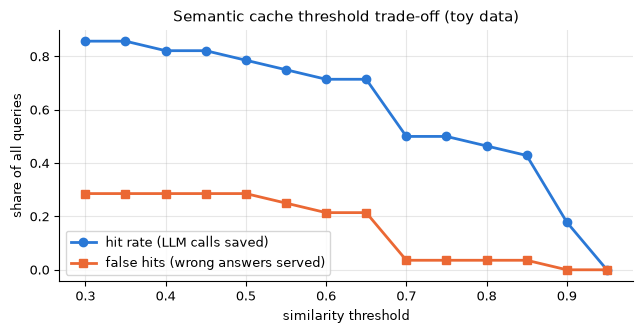

 threshold  hit rate  correct hits  false hits (wrong answer)  precision of hits
      0.30      0.86          0.57                       0.29               0.67
      0.35      0.86          0.57                       0.29               0.67
      0.40      0.82          0.54                       0.29               0.65
      0.45      0.82          0.54                       0.29               0.65
      0.50      0.79          0.50                       0.29               0.64
      0.55      0.75          0.50                       0.25               0.67
      0.60      0.71          0.50                       0.21               0.70
      0.65      0.71          0.50                       0.21               0.70
      0.70      0.50          0.46                       0.04               0.93
      0.75      0.50          0.46                       0.04               0.93
      0.80      0.46          0.43                       0.04               0.92
      0.85      0.43        

In [24]:
labels = np.array([-1 if lab is None else lab for _, lab in tests])
rows_t = []
for th in np.arange(0.30, 0.96, 0.05):
    hit = best_sim >= th
    correct = hit & (best_idx == labels)
    wrong = hit & (best_idx != labels)
    rows_t.append({"threshold": round(th, 2), "hit rate": hit.mean(),
                   "correct hits": correct.mean(), "false hits (wrong answer)": wrong.mean(),
                   "precision of hits": correct.sum() / max(hit.sum(), 1)})
sweep = pd.DataFrame(rows_t)

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(sweep["threshold"], sweep["hit rate"], marker="o", label="hit rate (LLM calls saved)")
ax.plot(sweep["threshold"], sweep["false hits (wrong answer)"], marker="s", label="false hits (wrong answers served)")
ax.set(xlabel="similarity threshold", ylabel="share of all queries", title="Semantic cache threshold trade-off (toy data)")
ax.legend(); plt.tight_layout(); plt.show()
print(sweep.round(2).to_string(index=False))

**How to read this:** a low threshold saves many LLM calls but serves wrong answers. A high threshold is safe but rarely hits. There is no free lunch; you pick a point based on **how bad a wrong answer is** in your product. In practice:
- Build a labeled set of real query pairs from your logs ("same intent" / "different intent").
- Pick the threshold that keeps false hits below a level you accept, then measure the hit rate you get.
- Re-check after changing the embedding model: similarity scores are not comparable across models.

### A small semantic cache with TTL, scopes and a "do not cache" rule

In [25]:
class SemanticCache:
    """Toy semantic cache. Entries are separated by SCOPE (tenant + permission group) and expire after a TTL."""
    PERSONAL = ("my balance", "my account balance", "my salary", "my order status", "today", "now", "latest")

    def __init__(self, vectorizer, threshold=0.75, ttl_s=3600):
        self.vec, self.threshold, self.ttl_s = vectorizer, threshold, ttl_s
        self.entries = []                      # dicts: scope, question, answer, created, emb

    def cacheable(self, question):
        q = question.lower()
        return not any(p in q for p in self.PERSONAL)    # personal or time-sensitive -> never cache

    def lookup(self, question, scope, now):
        emb = self.vec.transform([question])
        best, best_s = None, -1.0
        for e in self.entries:
            if e["scope"] != scope or now - e["created"] > self.ttl_s:
                continue                                  # other users' scope or expired: invisible
            s = cosine_similarity(emb, e["emb"])[0, 0]
            if s > best_s:
                best, best_s = e, s
        return (best["answer"], best_s) if best and best_s >= self.threshold else (None, best_s)

    def store(self, question, answer, scope, now):
        if self.cacheable(question):
            self.entries.append({"scope": scope, "question": question, "answer": answer,
                                 "created": now, "emb": self.vec.transform([question])})

llm_calls = 0
def fake_llm(question, scope):
    """Stand-in for a real LLM call (no API). Counts calls so we can see savings."""
    global llm_calls; llm_calls += 1
    return f"<LLM answer for {scope}: {question}>"

def ask(cache, question, scope, now):
    if cache.cacheable(question):
        ans, s = cache.lookup(question, scope, now)
        if ans is not None:
            return f"HIT  ({s:.2f}) {ans}"
    ans = fake_llm(question, scope)
    cache.store(question, ans, scope, now)
    return "MISS " + ans

sc = SemanticCache(vec, threshold=0.75, ttl_s=3600)
events = [
    ("How do I reset my password?",                 "acme/public", 0),
    ("how can I reset my password",                 "acme/public", 60),     # paraphrase -> hit
    ("What is the salary band for level 5?",        "acme/hr-only", 100),
    ("What is the salary band for level 5?",        "acme/public", 120),    # same text, other scope -> miss
    ("What is my account balance?",                 "acme/public", 130),    # personal -> never cached
    ("What is my account balance?",                 "acme/public", 140),
    ("how can I reset my password",                 "acme/public", 7200),   # older than TTL -> miss
]
for q, scope, t in events:
    print(f"t={t:>5}s {scope:13s} {q[:38]:38s} -> {ask(sc, q, scope, t)[:70]}")
print("LLM calls:", llm_calls, "of", len(events), "questions")

t=    0s acme/public   How do I reset my password?            -> MISS <LLM answer for acme/public: How do I reset my password?>
t=   60s acme/public   how can I reset my password            -> HIT  (0.85) <LLM answer for acme/public: How do I reset my password?>
t=  100s acme/hr-only  What is the salary band for level 5?   -> MISS <LLM answer for acme/hr-only: What is the salary band for level 5
t=  120s acme/public   What is the salary band for level 5?   -> MISS <LLM answer for acme/public: What is the salary band for level 5?
t=  130s acme/public   What is my account balance?            -> MISS <LLM answer for acme/public: What is my account balance?>
t=  140s acme/public   What is my account balance?            -> MISS <LLM answer for acme/public: What is my account balance?>
t= 7200s acme/public   how can I reset my password            -> MISS <LLM answer for acme/public: how can I reset my password>
LLM calls: 6 of 7 questions


### Risks and when NOT to use a semantic cache

- **Privacy and permissions:** never share cached answers across users with different access rights. An answer built from an HR-only document must not be served to a public user just because the question matches. Put the **tenant and permission group in the cache key** (the `scope` above), or cache only answers built from public data.
- **Personalization:** "what is *my* balance" has a different correct answer for every user. Do not cache it, or scope it per user.
- **Staleness:** cached answers go out of date when prices, policies or documents change. Use a TTL and **invalidate** (delete) entries when the source data changes.
- **Context-dependent questions:** in a multi-turn chat, "what about the second one?" means different things in different chats. Embed the question *with* the needed context, or skip the cache.
- **Actions and tools:** never cache the result of an action ("transfer 100 dollars", "book a room").
- **Creative tasks:** users who ask for a new poem do not want the same one twice.
- **High-stakes domains** (medical, legal, financial advice): a false hit is expensive; keep the threshold very high or do not use a semantic cache.

A common safe pattern: exact-match cache first (cheap, no false hits), semantic cache second (only for FAQ-like, public, stable questions), then the LLM.

### Exact-match vs semantic vs prompt vs KV cache (and CAG)

| | Exact-match cache | Semantic cache | Prompt / prefix cache | KV cache | CAG |
|---|---|---|---|---|---|
| What is cached | final answer for identical text | final answer for similar meaning | KV of an identical prompt start | K,V of every token in one request | KV of a whole preloaded knowledge base |
| Where it lives | your app (Redis, a dict) | your app + vector index | provider or serving engine | GPU memory during generation | serving engine (or provider prompt cache) |
| Skips | the whole LLM call | the whole LLM call | prefill of the cached part | recomputing past tokens | prefill of the knowledge base, and retrieval |
| Speedup on hit | very large | very large | lower TTFT, cheaper input | essential for any decode speed | lower TTFT per question |
| Can give a wrong answer? | only if stale | yes, false hits | no (same output as without it) | no | no extra risk (but long context can confuse the model) |
| Main risk | staleness | false hits, privacy leaks across users | small prompt changes kill the hit rate | memory use | knowledge must fit in context; stale preload |

## 7. Cache-Augmented Generation (CAG)

**What it is:** instead of retrieving a few chunks for every question (RAG), you **load the whole (small) knowledge base into the context once**, run prefill once, and **keep its KV cache**. Every question is then appended to that cached prefix. After answering, you cut the cache back to the end of the knowledge base and reuse it for the next question. The paper "Don't Do RAG: When Cache-Augmented Generation is All You Need for Knowledge Tasks" (Chan et al., 2024) describes this approach.

**Simple analogy:** RAG = a student who runs to the library for each exam question. CAG = a student who read the whole (short) textbook before the exam and keeps it in their head.

```mermaid
flowchart LR
    subgraph Once["Once"]
        KB[Knowledge base text] --> PF[Prefill] --> KVC[(KV cache of knowledge base)]
    end
    subgraph Each["For each question"]
        Q[Question] --> APP[Append to cached prefix] --> DEC[Decode answer] --> TR[Cut cache back to knowledge base]
    end
    KVC --> APP
```

For the many RAG variants, see [Every RAG Type Explained](02_rag/05_every_rag_type_explained.ipynb).

We simulate CAG with our numpy model: a 2,000-token "knowledge base", 20 questions of 15 tokens, 8 answer tokens each. We compare:
- **Full context, no reuse:** prefill knowledge base + question for every question.
- **CAG:** prefill knowledge base once, reuse its KV cache.
- **RAG (toy):** prefill only 3 retrieved chunks of 100 tokens + question. (Answers will differ, because the context differs; we only compare cost here.)

In [26]:
kb = list(rng.integers(0, 64, size=2_000))                          # stand-in for documents
questions = [list(rng.integers(0, 64, size=15)) for _ in range(20)]

def answer_from_cache(model, prefix_cache, question, n_new=8):
    """Append the question to a prefix cache and decode greedily. The prefix arrays are not changed,
    because vstack makes new arrays: this is the 'cut back to the knowledge base' step for free."""
    cache = {"K": prefix_cache["K"], "V": prefix_cache["V"]}
    logits = model.next_logits_with_cache(question, cache)
    out = []
    for _ in range(n_new):
        nxt = int(np.argmax(logits)); out.append(nxt)
        logits = model.next_logits_with_cache([nxt], cache)
    return out

results = {}
# A) full context every time
model.kv_rows_computed = 0; t0 = time.perf_counter()
ans_full = [answer_from_cache(model, empty_cache(model.d), kb + q) for q in questions]
results["full context, no reuse"] = (model.kv_rows_computed, time.perf_counter() - t0, len(kb) + 15)

# B) CAG: prefill the knowledge base ONCE
model.kv_rows_computed = 0; t0 = time.perf_counter()
kb_cache = empty_cache(model.d); model.next_logits_with_cache(kb, kb_cache)
ans_cag = [answer_from_cache(model, kb_cache, q) for q in questions]
results["CAG (preloaded KV)"] = (model.kv_rows_computed, time.perf_counter() - t0, len(kb) + 15)

# C) toy RAG: 3 'retrieved' chunks of 100 tokens per question
model.kv_rows_computed = 0; t0 = time.perf_counter()
for i, q in enumerate(questions):
    starts = rng.choice(len(kb) // 100, size=3, replace=False) * 100
    ctx = [t for s in starts for t in kb[s:s + 100]]
    answer_from_cache(model, empty_cache(model.d), ctx + q)
results["RAG (3 x 100-token chunks)"] = (model.kv_rows_computed, time.perf_counter() - t0, 300 + 15)

print("CAG answers identical to full-context answers:", ans_cag == ans_full)
print(pd.DataFrame([{"approach": k, "K/V rows computed (20 questions)": v[0], "time (ms)": round(v[1] * 1000, 1),
                     "keys read per answer token": v[2]} for k, v in results.items()]).to_string(index=False))

CAG answers identical to full-context answers: True
                  approach  K/V rows computed (20 questions)  time (ms)  keys read per answer token
    full context, no reuse                             40460       42.4                        2015
        CAG (preloaded KV)                              2460       34.3                        2015
RAG (3 x 100-token chunks)                              6460       19.7                         315


**What this shows:**
- CAG gives the **same answers** as putting the whole knowledge base in every prompt, while computing its K/V only once.
- RAG computes even fewer rows and each answer token reads far fewer keys, because its context is small. CAG still pays for **attention over the whole knowledge base** at every decode step, and must **hold** that KV cache in memory.

At the API level, CAG is simply "long static context + prompt caching". A quick cost comparison for 1,000 questions over a 50,000-token knowledge base (**made-up prices** from section 5):

In [27]:
n_q, kb_tok, q_tok, rag_ctx, out_tok = 1_000, 50_000, 50, 1_500, 200
p_in, p_out = PRICE["input"] / 1e6, PRICE["output"] / 1e6
cost = {
    "full KB in every prompt, no caching": n_q * (kb_tok + q_tok) * p_in,
    "CAG = full KB + prompt caching (1 write, rest reads)":
        kb_tok * p_in * PRICE["cache_write_mult"] + (n_q - 1) * kb_tok * p_in * PRICE["cache_read_mult"] + n_q * q_tok * p_in,
    "RAG with 1,500 retrieved tokens": n_q * (rag_ctx + q_tok) * p_in,
}
for k, v in cost.items():
    print(f"{k:55s}: input ${v:7.2f} + output ${n_q * out_tok * p_out:.2f}")
print("(assumes requests come often enough to stay within the cache TTL)")

full KB in every prompt, no caching                    : input $ 100.10 + output $1.60
CAG = full KB + prompt caching (1 write, rest reads)   : input $  10.21 + output $1.60
RAG with 1,500 retrieved tokens                        : input $   3.10 + output $1.60
(assumes requests come often enough to stay within the cache TTL)


| | CAG | RAG |
|---|---|---|
| Retrieval step | none, so no retrieval misses | needed; can miss the right chunk |
| Knowledge size | must fit in the context window (and the model must use long context well) | practically unlimited |
| Per-question cost | low with caching, but every token attends over the whole KB | lowest token count |
| Latency | low TTFT after the first load; no retrieval round trip | retrieval + prefill each time |
| Updates | re-preload when the KB changes | update the index incrementally |
| Memory | one big KV cache kept warm | small per request |
| Access control | hard: everything is in context for everyone | easy: filter retrieved chunks per user |

**CAG tends to beat RAG when:** the knowledge base is small and stable (a product manual, a policy handbook, one long contract), questions come often, every answer may need facts spread across the whole document, and all users may see all of it.
**Stay with RAG when:** the corpus is large or changes often, users have different permissions, or you need citations to specific chunks with tight cost control.

## 8. Speculative decoding vs quantization

Both make generation cheaper or faster, but they trade very different things.

**Speculative decoding** (survey notebook: [13_inference_optimization](13_inference_optimization.ipynb)):
- **What it is:** a small, fast **draft model** guesses the next k tokens; the big **target model** checks all k guesses in **one** forward pass (cheap, because a forward pass over k tokens costs about the same as over 1 in the memory-bound decode phase). Correct guesses are kept; at the first wrong guess, the target picks a corrected token.
- **Simple analogy:** a junior writes the next few words of a sentence; the senior reads them all at once and keeps the good ones. The senior's style is preserved because the senior approves every word.
- **Trade-off:** with the standard acceptance rule the **output distribution is exactly the target model's**. You gain latency, but you need a draft model (more memory, more engineering) and extra compute for rejected guesses. It helps most at small batch sizes, when the GPU has spare compute.

**Quantization:**
- **What it is:** store model weights (and maybe activations / KV) in fewer bits, such as INT8, INT4 or FP8.
- **Trade-off:** less memory and lower cost (fit on a smaller GPU, bigger batches, faster memory-bound decode), but the model is *changed*, so there **may be some quality loss**, especially at 4 bits and below.

### A tiny speculative-decoding simulation

Our "models" are just **probability tables**: given the previous token, a row gives the probability of each next token (a bigram model). The draft is a noisy copy of the target. We use the standard accept/reject rule from the speculative sampling papers.

In [28]:
V_SIZE = 10
r = np.random.default_rng(7)
P_target = r.dirichlet(np.full(V_SIZE, 0.3), size=V_SIZE)     # peaky "big model" table
noise_tbl = r.dirichlet(np.full(V_SIZE, 0.3), size=V_SIZE)   # an unrelated peaky table (a "wrong" model)

def make_draft(noise):
    """noise = 0 -> perfect draft; noise = 1 -> draft knows nothing about the target."""
    return (1 - noise) * P_target + noise * noise_tbl

def speculative_generate(P, Q, n_tokens, k, rng, start=0):
    out, target_calls, checked, accepted = [start], 0, 0, 0
    while len(out) - 1 < n_tokens:
        ctx, draft = out[-1], []
        for _ in range(k):                                  # 1) draft guesses k tokens
            t = rng.choice(V_SIZE, p=Q[ctx]); draft.append(t); ctx = t
        target_calls += 1                                   # 2) ONE target pass checks all k
        ctx, all_ok = out[-1], True
        for t in draft:
            p, q = P[ctx], Q[ctx]; checked += 1
            if rng.random() < min(1.0, p[t] / q[t]):        # accept with prob min(1, p/q)
                out.append(t); accepted += 1; ctx = t
            else:                                           # reject: sample from the leftover p - q
                resid = np.maximum(p - q, 0); resid /= resid.sum()
                out.append(rng.choice(V_SIZE, p=resid)); all_ok = False; break
        if all_ok:
            out.append(rng.choice(V_SIZE, p=P[ctx]))        # bonus token from the same pass
    seq = out[1:n_tokens + 1]
    return seq, {"acceptance": accepted / checked, "tokens per target call": n_tokens / target_calls}

def plain_generate(P, n_tokens, rng, start=0):
    out = [start]
    for _ in range(n_tokens):
        out.append(rng.choice(V_SIZE, p=P[out[-1]]))
    return out[1:]

def transitions(seq, start=0):
    M = np.zeros((V_SIZE, V_SIZE))
    for a, b in zip([start] + seq[:-1], seq):
        M[a, b] += 1
    return M / M.sum(axis=1, keepdims=True)

g = np.random.default_rng(0)
spec_seq, stats = speculative_generate(P_target, make_draft(0.5), 20_000, k=4, rng=g)
plain_seq = plain_generate(P_target, 20_000, g)
tv = lambda M: 0.5 * np.abs(M - P_target).sum(axis=1).mean()   # total variation distance
print(f"distance from target distribution  plain sampling: {tv(transitions(plain_seq)):.3f}   speculative: {tv(transitions(spec_seq)):.3f}")
print(f"(both small and similar = same distribution; only sampling noise)   draft stats: {stats}")

distance from target distribution  plain sampling: 0.022   speculative: 0.021
(both small and similar = same distribution; only sampling noise)   draft stats: {'acceptance': 0.6698271658449368, 'tokens per target call': 2.6184865147944487}


 draft noise  acceptance rate  tokens per target call  estimated speedup
         0.0             1.00                    5.00               3.57
         0.2             0.86                    3.81               2.72
         0.4             0.73                    2.92               2.08
         0.6             0.62                    2.39               1.71
         0.8             0.47                    1.85               1.32
         1.0             0.36                    1.54               1.10


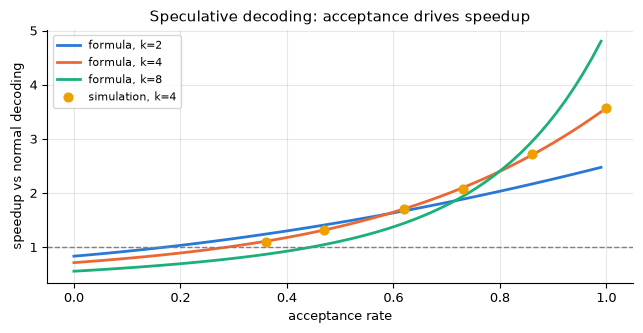

In [29]:
K_DRAFT, DRAFT_COST = 4, 0.10      # draft pass costs 10% of a target pass (ILLUSTRATIVE)
sim = []
for noise in [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]:
    _, st = speculative_generate(P_target, make_draft(noise), 4_000, k=K_DRAFT, rng=np.random.default_rng(1))
    sim.append({"draft noise": noise, "acceptance rate": round(st["acceptance"], 2),
                "tokens per target call": round(st["tokens per target call"], 2),
                "estimated speedup": round(st["tokens per target call"] / (1 + K_DRAFT * DRAFT_COST), 2)})
sim = pd.DataFrame(sim)
print(sim.to_string(index=False))

alpha = np.linspace(0.0, 0.99, 60)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for k, m in [(2, None), (4, None), (8, None)]:
    expected = (1 - alpha ** (k + 1)) / (1 - alpha)       # expected tokens per target call (Leviathan et al.)
    ax.plot(alpha, expected / (1 + k * DRAFT_COST), label=f"formula, k={k}")
ax.scatter(sim["acceptance rate"], sim["estimated speedup"], color=COLORS[3], zorder=3, s=40, label="simulation, k=4")
ax.axhline(1, color="gray", lw=1, ls="--")
ax.set(xlabel="acceptance rate", ylabel="speedup vs normal decoding", title="Speculative decoding: acceptance drives speedup")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**What this shows:** a good draft (high acceptance) gives a real speedup. A poor draft gives little gain, and below an acceptance rate of roughly 0.2 to 0.45 (depending on k, with our made-up draft cost) the curves drop under the dashed line: speculation is then *slower* than normal decoding. More draft tokens (bigger k) only pay off when acceptance is high. The output quality is the same in every case; only speed changes.

**Drafting methods (as of late 2026):**
- **Separate small draft model** from the same family (classic approach).
- **Medusa:** extra prediction heads on the target model guess several future tokens; no separate model.
- **EAGLE (and later versions):** a small head that drafts from the target model's internal features; often high acceptance.
- **N-gram / prompt lookup decoding:** no model at all; copy the tokens that followed the same few words earlier in the prompt. Great for summarizing, editing code and RAG answers that quote the context.

A tiny prompt-lookup drafter:

In [30]:
def prompt_lookup_draft(prompt_tokens, generated, n=2, k=4):
    """Find the last n generated tokens inside the prompt and propose the k tokens that followed."""
    key = generated[-n:]
    for i in range(len(prompt_tokens) - n, -1, -1):
        if prompt_tokens[i:i + n] == key:
            return prompt_tokens[i + n:i + n + k]
    return []

doc = "the invoice for acme corp was paid on march 3 by bank transfer to account 42".split()
so_far = "summary : acme corp".split()
print("generated so far:", so_far)
print("drafted for free:", prompt_lookup_draft(doc, so_far))

generated so far: ['summary', ':', 'acme', 'corp']
drafted for free: ['was', 'paid', 'on', 'march']


### Quantization in the same toy setting

We quantize the weights of our tiny attention model to INT8 and INT4 and check how often it still picks the same next token as the full-precision model.

In [31]:
def quantize_weights(m, bits):
    q = TinyAttentionLM(); q.__dict__.update({k: v for k, v in m.__dict__.items()})
    for name in ["Wq", "Wk", "Wv", "Wo", "W_out"]:
        setattr(q, name, fake_quantize(getattr(m, name), bits, axis=0))   # one scale per output column
    return q

def next_token_choices(m, tokens):
    cache, picks = empty_cache(m.d), []
    for t in tokens:
        picks.append(int(np.argmax(m.next_logits_with_cache([t], cache))))
    return np.array(picks)

seq_tokens = list(rng.integers(0, 64, size=300))
ref_picks = next_token_choices(model, seq_tokens)
n_weights = sum(getattr(model, n).size for n in ["Wq", "Wk", "Wv", "Wo", "W_out"])
for bits, label in [(16, "FP16 (reference)"), (8, "INT8"), (4, "INT4")]:
    picks = ref_picks if bits == 16 else next_token_choices(quantize_weights(model, bits), seq_tokens)
    print(f"{label:17s} weight memory {n_weights * bits / 8 / 1024:5.1f} KiB | same next token as FP16: {np.mean(picks == ref_picks):.0%}")

FP16 (reference)  weight memory  12.0 KiB | same next token as FP16: 100%


INT8              weight memory   6.0 KiB | same next token as FP16: 100%
INT4              weight memory   3.0 KiB | same next token as FP16: 88%


This toy has random weights, so the exact percentages mean little. The pattern is the general one: 8 bits is usually close to the original, 4 bits saves more memory but changes more decisions. Real 4-bit methods (GPTQ, AWQ and others) work hard to reduce this loss; always evaluate on your own task.

| Question | Speculative decoding | Quantization |
|---|---|---|
| Changes the output? | no (same distribution with standard rule) | yes, slightly (possible quality loss) |
| Main win | lower latency per user | less memory, lower cost, often faster too |
| Extra cost | draft model or heads, wasted compute on rejections | calibration, quality evaluation |
| Best when | small batches, latency-sensitive chat, predictable text (code, quoting) | memory-limited GPUs, high-throughput serving, edge devices |
| Weak when | big batches (GPU already busy), low acceptance | quality-critical tasks at very low bit widths |
| Combine? | yes, they stack: a quantized target with a speculative draft is common | |

**Decision shortcut:** "model does not fit or costs too much" -> quantize first. "Fits fine but each user waits too long for tokens" -> add speculative decoding. Many production systems do both.

## 9. Measuring it: a small simulated dashboard

You cannot improve what you do not measure. One-line definitions:
- **TTFT (time to first token):** from sending the request to receiving the first output token. Mostly queue time + prefill.
- **ITL (inter-token latency)** or **TPOT (time per output token):** average time between output tokens during decode.
- **Tokens/sec:** output speed. Per stream (what one user sees) or total across the server (throughput).
- **Cache hit rate:** for prefix/prompt caching, the share of prompt tokens served from cache; for a semantic cache, the share of questions answered from cache.
- **Cost per 1M tokens:** what you actually pay, averaged over input, cached input and output tokens.

Serving engines such as vLLM and SGLang expose metrics like these (TTFT histograms, prefix-cache hit rate, KV-cache usage) for tools like Prometheus; hosted APIs report cached tokens in each response's usage data.

Below, a **simulated** request log with a **made-up** latency model, comparing "no caching" with "prefix caching + semantic cache".

In [32]:
def simulate_traffic(prefix_cache, semantic_cache, n=400, seed=5):
    r = np.random.default_rng(seed)
    rows = []
    for _ in range(n):
        prompt, out = 2_000 + int(r.integers(50, 400)), max(20, int(r.normal(200, 50)))
        if semantic_cache and r.random() < 0.15:          # 15% answered from semantic cache (toy)
            rows.append(dict(ttft=0.02, itl=0.0, out=out, prompt=prompt, cached=prompt, llm=False)); continue
        cached = 2_000 if (prefix_cache and r.random() < 0.85) else 0   # shared system prompt hit
        queue = r.exponential(0.05)
        ttft = queue + (prompt - cached) / 20_000         # ILLUSTRATIVE prefill speed 20k tok/s
        itl = 0.020 + 0.000002 * prompt + r.normal(0, 0.002)
        rows.append(dict(ttft=ttft, itl=itl, out=out, prompt=prompt, cached=cached, llm=True))
    return pd.DataFrame(rows)

def dashboard(df, name):
    llm = df[df.llm]
    in_uncached, in_cached = (llm.prompt - llm.cached).sum(), llm.cached.sum()
    cost = (in_uncached * PRICE["input"] + in_cached * PRICE["input"] * PRICE["cache_read_mult"]
            + llm.out.sum() * PRICE["output"]) / 1e6       # made-up prices; semantic hits cost ~0
    return {"setup": name, "p50 TTFT (ms)": round(df.ttft.median() * 1000), "p95 TTFT (ms)": round(df.ttft.quantile(0.95) * 1000),
            "mean ITL (ms)": round(llm.itl.mean() * 1000, 1), "tokens/s per stream": round(1 / llm.itl.mean()),
            "prefix hit rate": f"{in_cached / llm.prompt.sum():.0%}", "semantic hit rate": f"{1 - df.llm.mean():.0%}",
            "LLM cost ($)": round(cost, 2),
            "cost per 1M tokens ($)": round(cost / (df.prompt.sum() + df.out.sum()) * 1e6, 3)}

dash = pd.DataFrame([dashboard(simulate_traffic(False, False), "no caching"),
                     dashboard(simulate_traffic(True, False), "prefix caching"),
                     dashboard(simulate_traffic(True, True), "prefix + semantic cache")])
print(dash.to_string(index=False))

                  setup  p50 TTFT (ms)  p95 TTFT (ms)  mean ITL (ms)  tokens/s per stream prefix hit rate semantic hit rate  LLM cost ($)  cost per 1M tokens ($)
             no caching            146            259           24.5                   41              0%                0%          2.42                   2.498
         prefix caching             54            190           24.4                   41             77%                0%          1.18                   1.219
prefix + semantic cache             43            172           24.4                   41             77%               13%          1.03                   1.064


**How to read it:** prefix caching mainly cuts TTFT and input cost; it does not change ITL much (decode still reads the full KV cache). The semantic cache removes some LLM calls completely, which helps both latency and cost, but it is the only layer that can return a *wrong* answer, so track its false-hit rate with spot checks too.

Things worth alerting on: a sudden drop in prefix hit rate (someone changed the prompt start), rising p95 TTFT (queueing or long prompts), rising KV-cache usage (memory pressure, coming evictions), and cost per 1M tokens drifting up. Cost monitoring and hidden token usage in general are a topic of their own; see [LLM Evaluation Hands-On](22_llm_evaluation_hands_on.ipynb) for evaluation practice.

## Recap: cheat sheet

| Concept | One-line meaning | Remember |
|---|---|---|
| KV cache | stored keys and values of past tokens | same output, removes n-squared recomputation, costs memory |
| Prefill | process the whole prompt in parallel | compute bound, drives TTFT |
| Decode | generate one token at a time | memory-bandwidth bound, drives ITL |
| KV memory formula | 2 x layers x kv_heads x head_dim x seq x batch x bytes | grows linearly with length and users |
| MQA / GQA | share K/V heads across query heads | 4-32x smaller cache, chosen at training time |
| MLA | cache a small latent, rebuild K/V | very small cache (DeepSeek-V2 and later) |
| Sliding window / hybrid linear | cap or remove the growing cache | may weaken far recall |
| PagedAttention | KV in fixed blocks + block table | almost no fragmentation, more users per GPU |
| Prefix caching / RadixAttention | share KV of identical prompt starts | put static content first |
| LRU eviction | drop least recently used unused blocks | capacity matters most |
| KV quantization | FP8/INT8/INT4 K and V | 2-4x more room; check quality |
| Tiered offload (LMCache idea) | move KV to CPU/SSD instead of deleting | reload vs recompute |
| KV-aware routing | send same prefix to same replica | balance with load limits |
| Disaggregated prefill/decode | separate GPU pools, transfer KV | phases stop interfering |
| Chunked prefill | split long prompts into chunks | protects other users' ITL |
| Prompt caching (API) | provider reuses identical prefixes | write premium, cheap reads, TTL |
| Semantic cache | reuse answers for similar questions | threshold trade-off, scope by permissions |
| CAG | preload small KB once, reuse its KV | no retrieval; KB must fit and be shared by all users |
| Speculative decoding | draft guesses, target verifies | same distribution, latency win |
| Quantization | fewer bits per weight | less memory/cost, possible quality loss |

## Interview questions

1. **Why does a KV cache not change the model's output?** Past tokens' keys and values do not depend on future tokens (causal attention), so computing them once and reusing them gives exactly the same numbers.
2. **Why is decode memory-bandwidth bound?** Each step does a little math per weight but must read all weights and the KV cache from memory for only one token per request. Batching many requests shares that read.
3. **Estimate KV cache size for 32 layers, 8 KV heads, head_dim 128, 32k tokens, FP16.** 2 x 32 x 8 x 128 x 32,768 x 2 bytes = 4 GiB per request.
4. **GQA vs MLA?** GQA shares K/V heads among groups of query heads; MLA caches a low-dimensional latent per token and reconstructs K/V with learned up-projections. Both must be built into the model before or during training.
5. **What problem does PagedAttention solve?** Fragmentation from reserving maximum length contiguous memory; fixed blocks with a block table let memory be allocated on demand and shared between requests.
6. **How would you raise the prompt-cache hit rate of an agent?** Keep system prompt and tool definitions identical and first, avoid timestamps/ids at the start, keep tool order fixed, append history rather than rewriting it, and monitor cached-token counts.
7. **When can prompt caching cost more?** When requests are further apart than the TTL, so you keep paying the write premium without reads, or when prefixes are never reused.
8. **Main risks of a semantic cache?** False hits (wrong answers for similar-looking questions), cross-user leaks of permissioned or personal data, and stale answers. Mitigate with a tuned threshold, scope in the key, TTL and invalidation, and do-not-cache rules.
9. **When does CAG beat RAG?** Small, stable, shared knowledge that fits in context, many questions, and answers needing facts from across the document. RAG wins for large, changing or permissioned corpora.
10. **Speculative decoding vs quantization: which first?** Quantize when memory/cost is the problem; add speculative decoding when per-user latency is the problem and acceptance is high. They can be combined.

## Further reading

- Kwon et al. (2023), *Efficient Memory Management for Large Language Model Serving with PagedAttention* (the vLLM paper), arXiv:2309.06180.
- Zheng et al. (2023), *SGLang: Efficient Execution of Structured Language Model Programs* (RadixAttention), arXiv:2312.07104.
- DeepSeek-AI (2024), *DeepSeek-V2: A Strong, Economical, and Efficient Mixture-of-Experts Language Model* (multi-head latent attention), arXiv:2405.04434.
- Shazeer (2019), *Fast Transformer Decoding: One Write-Head is All You Need* (MQA), arXiv:1911.02150.
- Ainslie et al. (2023), *GQA: Training Generalized Multi-Query Transformer Models from Multi-Head Checkpoints*, arXiv:2305.13245.
- Pope et al. (2022), *Efficiently Scaling Transformer Inference* (memory-bound decoding, KV cache costs), arXiv:2211.05102.
- Chan et al. (2024), *Don't Do RAG: When Cache-Augmented Generation is All You Need for Knowledge Tasks*, arXiv:2412.15605.
- Leviathan, Kalman and Matias (2023), *Fast Inference from Transformers via Speculative Decoding*, arXiv:2211.17192.
- Chen et al. (2023), *Accelerating Large Language Model Decoding with Speculative Sampling*, arXiv:2302.01318.
- Cai et al. (2024), *Medusa: Simple LLM Inference Acceleration Framework with Multiple Decoding Heads*, arXiv:2401.10774.
- Li et al. (2024), *EAGLE: Speculative Sampling Requires Rethinking Feature Uncertainty*, arXiv:2401.15077.
- Agrawal et al., *SARATHI* and *Sarathi-Serve* (chunked prefill); Zhong et al., *DistServe*, and Patel et al., *Splitwise* (disaggregated prefill/decode).
- Liu et al., *KIVI* (KV cache quantization); the LMCache project (tiered, shareable KV cache); GPTCache (an open-source semantic cache library).
- Provider documentation on prompt caching (for example Anthropic's and OpenAI's prompt caching guides) for current prices, TTLs and minimum lengths.
- In this repo: [LLM Inference Optimization](13_inference_optimization.ipynb), [LLM Architecture Innovations](14_llm_architecture_innovations.ipynb), [Every RAG Type Explained](02_rag/05_every_rag_type_explained.ipynb), [Industry RAG Pipeline](19_industry_rag_pipeline.ipynb).